This tutorial uses KaleCardiac to pretrain, fine-tune, evaluate and interpret LS-EMVAE [1], a lead-specific multimodal variational autoencoder (VAE) that reads a twelve-lead electrocardiogram (ECG) as twelve modalities, one per lead. The model is pretrained on all twelve leads and fine-tuned on the six limb leads that a low-cost recorder captures, or on all twelve with a single setting.

LS-EMVAE has four core components, all used here:

- **an encoder for each lead**;
- **hierarchical modality experts (HiME)**, which fuse the leads' latent posteriors;
- **one decoder shared by every lead**;
- **a latent alignment term**, which keeps each lead's posterior close to the joint posterior.

A twelve-lead ECG is usually modelled as one twelve-channel signal, as if its leads were interchangeable channels of a single view. Each lead, however, projects the heart's electrical activity onto a different axis, so LS-EMVAE treats the leads as *different views of the same cardiac state*, the setting a multimodal VAE is designed for. This brings two advantages over the channel view:

- **An encoder for each lead that keeps working when other leads are absent**, which makes a model pretrained on twelve leads usable on six, or on one.
- **A principled fusion of the leads' evidence:** a product of experts within groups of leads that view related regions of the heart, followed by an average across the groups, so that no single group decides the representation on its own.

The workflow starts from raw DICOM files, the format in which hospitals export ECGs, and each step takes a few calls to the KaleCardiac API:

- **Step 0: Environment preparation.** Install KaleCardiac and download the tutorial dataset.
- **Step 1: Multimodal pretraining.** Load the pretraining configuration and the unlabelled twelve-lead ECGs, split each ECG into its twelve leads and pretrain LS-EMVAE on all of them.
- **Step 2: Multimodal fine-tuning.** Load the fine-tuning configuration and the six limb leads, or all twelve, of the labelled ECGs, then fine-tune a classifier.
- **Step 3: Evaluation.** Score the held-out test subjects with the fine-tuning leads, and with fewer.
- **Step 4: Interpretation.** Identify which leads, and which parts of each lead, the predictions rely on.

**Estimated runtime:** about 10 minutes on a Colab T4 GPU, including installation. The estimates for individual steps below also refer to a T4 GPU.

## Step 0: Environment Preparation

### Runtime

In Google Colab, select **Runtime > Change runtime type > T4 GPU**. The tutorial also runs on a CPU, more slowly.

### Package installation

The cell below installs KaleCardiac from its GitHub repository with two optional extras: `imaging` (pydicom and scikit-image, required by PyKale's DICOM reader) and `interpret` (Captum, for integrated gradients). pip also installs the other dependencies the tutorial needs, such as PyKale and PyTorch Lightning. The cell then downloads this tutorial's folder, containing the notebook and its `configs`, and makes it the working directory.

Run this cell in Google Colab. When running locally, skip it: install KaleCardiac with `pip install -e ".[imaging,interpret]"` from a clone of its repository, and open the notebook from a folder that contains its `configs` folder, such as `tutorials/mdas_tutorial`.

**Estimated runtime:** 3 minutes

In [ ]:
!pip install --quiet "kalecardiac[imaging,interpret] @ git+https://github.com/pykale/cardiac@main"
!git clone --quiet --depth 1 --filter=blob:none --sparse https://github.com/pykale/cardiac
!git -C cardiac sparse-checkout set tutorials/mdas_tutorial
%cd cardiac/tutorials/mdas_tutorial

### Setup

The cell below silences warnings and PyTorch Lightning's start-up messages to keep the output readable, then reports the installed KaleCardiac version and the working directory, confirming that the installation succeeded.

In [1]:
import logging
import warnings
from pathlib import Path

import pytorch_lightning

import kalecardiac

warnings.filterwarnings("ignore")
# Importing Lightning sets its loggers' level, so they are quieted after it is imported.
for name in (pytorch_lightning.__name__, "lightning_fabric"):
    logging.getLogger(name).setLevel(logging.ERROR)
print(f"KaleCardiac {kalecardiac.__version__}, working in {Path.cwd()}")

KaleCardiac 0.1.0a0, working in M:\cardiac\tutorials\mdas_tutorial


### Dataset download

The tutorial dataset, shared with the CardioVAE tutorial, is a single ZIP archive. The cell below downloads it into the runtime's local storage, without any sign-in, and unpacks it into `data/` next to this notebook. If the dataset is already unpacked there, for example by the CardioVAE tutorial, nothing is downloaded.

```
data/
├── kalecardiac_pretraining/
│   ├── ECG/<subject>/.../*.dcm    one twelve-lead ECG per subject (DICOM ECG waveform)
│   └── CXR/<subject>/.../*.dcm    one chest X-ray per subject, not used in this tutorial
└── kalecardiac_finetuning/
    ├── ECG/<subject>/.../*.dcm
    ├── CXR/<subject>/.../*.dcm
    └── labels.csv                 subject_id,label
```

`kalecardiac_pretraining` holds the unlabelled ECGs for pretraining; `kalecardiac_finetuning` adds a label for each subject for fine-tuning. As in a hospital export, each subject has a folder named by its identifier. To use your own data instead, skip this cell and see *Your own data* below.

**Estimated runtime:** 1 minute

In [2]:
import urllib.request
import zipfile

# The tutorial dataset on Dropbox; "dl=1" asks Dropbox for the file itself rather than its web page.
DATA_URL = "https://www.dropbox.com/scl/fi/y488iouenrk641dxtd8ai/kalecardiac_tutorial_data.zip?rlkey=rorf5mvbt24jdw2cr3ecyy91n&st=yt83r37g&dl=1"

if not Path("data").is_dir():
    archive, _ = urllib.request.urlretrieve(DATA_URL, "kalecardiac_tutorial_data.zip")
    with zipfile.ZipFile(archive) as bundle:
        bundle.extractall("data")
print(sorted(folder.name for folder in Path("data").iterdir()))

['kalecardiac_finetuning', 'kalecardiac_pretraining']


### Your own data

The same steps run on your own ECGs, organised as in the tutorial dataset: an `ECG/` folder with one folder per subject containing that subject's DICOM ECG, and, for fine-tuning, a `labels.csv` file with a `subject_id` column and a column of classes (0 or 1). Skip the dataset download, and set your folders in the configuration cells of Step 1 and Step 2 by uncommenting the lines marked *Your own data*. Sampling rates are read from the DICOM headers, and recordings are resampled to the 500 Hz that LS-EMVAE reads. For ECGs recorded with six leads, as by a low-cost recorder, fine-tune with `USE_12_LEADS = False` in Step 2's configuration.

Use identifiable patient data only in an approved, secure environment, never on public services such as Colab.

## Step 1: Multimodal Pretraining

LS-EMVAE is pretrained without labels on the twelve-lead ECGs in `kalecardiac_pretraining`, with each lead as a modality of its own.

### Configuration

KaleCardiac reads every setting from a [YACS](https://github.com/rbgirshick/yacs) configuration, which keeps an experiment's settings separate from its code. The tutorial's configuration files are in its `configs` folder, and each is merged onto KaleCardiac's defaults (`kalecardiac.config`). Pretraining reads `configs/config_lsemvae_pretrain.yaml`: the unlabelled dataset; the twelve leads LS-EMVAE reads, in the order in which they are stacked as experts; each lead's length and sampling rate; the lead encoders; the hierarchical fusion; the objective with its latent alignment term; and the pretraining schedule.

Change a setting in the file, or override it in the cell below.

In [3]:
from kalecardiac.config import get_cfg_defaults

cfg_pt = get_cfg_defaults()
cfg_pt.merge_from_file("configs/config_lsemvae_pretrain.yaml")

# ------ Hyperparameters to play with -----
cfg_pt.MODEL.LATENT_DIM = 128
cfg_pt.FUSION.LATENT_METHOD = "hime"  # "poe" (no average across groups) and "moe" (no product) are its ablations
cfg_pt.OBJECTIVE.ALIGNMENT_WEIGHT = 0.1  # 0 drops the latent alignment term
cfg_pt.SOLVER.MAX_EPOCHS = 10
cfg_pt.SOLVER.BATCH_SIZE = 4
cfg_pt.OBJECTIVE.ANNEALING_EPOCHS = cfg_pt.SOLVER.MAX_EPOCHS  # the KL weight rises over the whole run

# ------ Your own data -----
# cfg_pt.DATASET.ROOT = "/path/to/your/pretraining_data"  # holds ECG/

print(f"DATASET.ROOT: {cfg_pt.DATASET.ROOT}\n")
for section in ("ECG", "FUSION", "OBJECTIVE", "SOLVER"):
    print(f"{section}:\n{cfg_pt[section]}\n")

DATASET.ROOT: data/kalecardiac_pretraining

ECG:
ENCODER: conv
LEADS: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
LENGTH: 5000
NORMALIZE: True
NUM_CHANNELS: 0
SAMPLING_RATE: 500
SOURCE_SAMPLING_RATE: 0

FUSION:
FUSION_DIM: 0
LATENT_METHOD: hime
METHOD: concat
MODALITY_DROPOUT: 0.0
NUM_GROUPS: 4
USE_PRIOR: True

OBJECTIVE:
ALIGNMENT_WEIGHT: 0.1
ANNEALING_EPOCHS: 10
POS_WEIGHT: 0.0
RECONSTRUCTION_WEIGHTS: []
SCALE_FACTOR: 0.001
UNIMODAL_STREAMS: False

SOLVER:
ACCELERATOR: auto
BASE_LR: 0.0005
BATCH_SIZE: 4
DEVICES: auto
EARLY_STOP: 0
GRAD_CLIP: 1.0
MAX_EPOCHS: 10
OPTIMIZER: AdamW
SEED: 123
WEIGHT_DECAY: 1e-05



### Data loading

`ECGFileSource.from_dicom`, in `kalecardiac.loaddata`, indexes the ECG folder by subject and reads a subject's file only when it is needed, so cohorts of any size load in the same way. Each file is read with PyKale's [3] DICOM reader, [`kale.loaddata.image_access.read_dicom_phases`](https://github.com/pykale/pykale/blob/main/kale/loaddata/image_access.py), and the twelve-lead rhythm waveform is extracted in millivolts, with each lead's name and the sampling rate read from the file's header. Leads are matched by *name*, so a file that stores aVF before aVL cannot transpose them, which matters all the more when each lead has an encoder of its own.

**Estimated runtime:** 10 seconds

In [4]:
from kalecardiac.loaddata import ECGFileSource

ecg_dir_pt = Path(cfg_pt.DATASET.ROOT, "ECG")
ecg_raw = ECGFileSource.from_dicom(ecg_dir_pt)
print(ecg_raw)

ECGFileSource(20 subjects | leads=['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'] | shape=12x5120 | 500 Hz)


One subject's ECG as loaded: its twelve leads, which LS-EMVAE reads as twelve modalities, with the limb leads on the left and the precordial leads on the right.

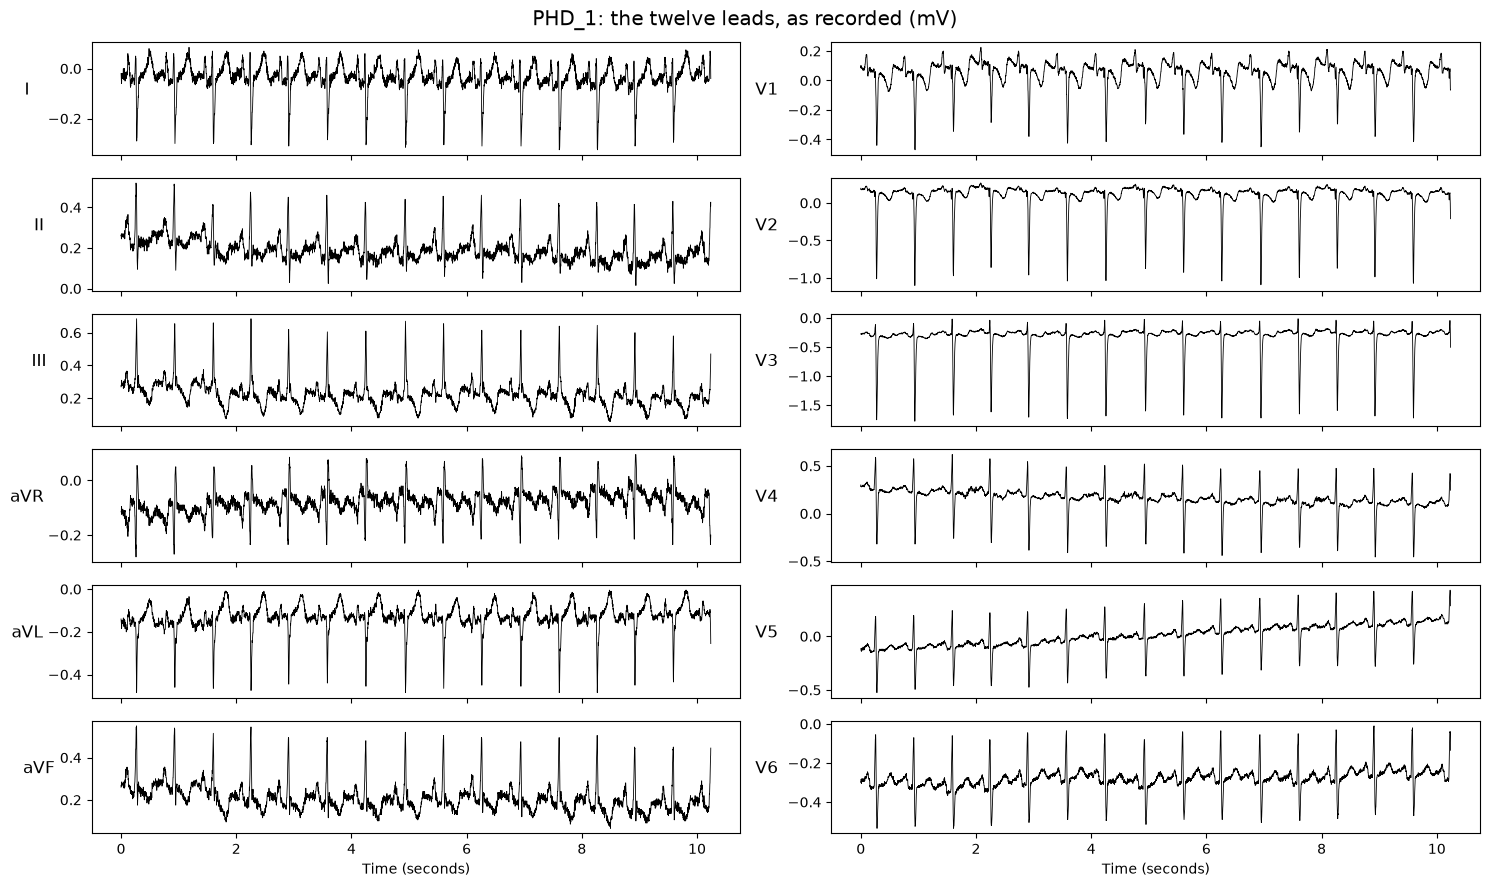

In [5]:
import matplotlib.pyplot as plt
import numpy as np

subject = sorted(ecg_raw.paths)[0]
recording = ecg_raw.get(subject, 0).numpy()
time = np.arange(recording.shape[1]) / ecg_raw.sampling_rate

fig, axes = plt.subplots(6, 2, figsize=(15, 9), sharex=True)
for index, lead in enumerate(cfg_pt.ECG.LEADS):
    ax = axes[index % 6, index // 6]
    ax.plot(time, recording[ecg_raw.leads.index(lead)], color="black", linewidth=0.6)
    ax.set_ylabel(lead, rotation=0, labelpad=15, fontsize="large")
for ax in axes[-1]:
    ax.set_xlabel("Time (seconds)")
fig.suptitle(f"{subject}: the twelve leads, as recorded (mV)", fontsize="x-large")
plt.tight_layout()
plt.show()

### Data preparation

For each subject, LS-EMVAE reads every lead as ten seconds recorded at 500 Hz, which gives 5,000 time points per lead, normalized lead by lead. Two KaleCardiac calls build these inputs from the configuration:

- `get_ecg_transform_from_cfg` (`kalecardiac.auto`) reads `cfg.ECG`: it fills any missing values in the signal, resamples a recording made at another rate to 500 Hz, crops or pads each lead to ten seconds, and normalizes each lead to zero mean and unit variance. Every step works on one lead at a time, and with `ECG.NUM_CHANNELS` set to 0 the leads stay apart, one channel each, rather than being interleaved into one strip as for CardioVAE. The leads are taken by name, in the order of `ECG.LEADS`.
- `get_lead_sources` (`kalecardiac.loaddata`) splits the recording into one source per lead, named after the lead.

`MultimodalDataset` then treats the twelve leads like any other set of modalities: each subject yields twelve, `I` to `V6`, each a single lead of 5,000 time points. From this point on, nothing in the pipeline depends on the modalities being ECG leads.

**Estimated runtime:** 10 seconds

In [6]:
from kalecardiac.auto import get_ecg_transform_from_cfg
from kalecardiac.loaddata import MultimodalDataset, get_lead_sources

# The rate the recordings were made at, as their DICOM headers state it, so any other is resampled.
cfg_pt.ECG.SOURCE_SAMPLING_RATE = ecg_raw.sampling_rate
ecg_transform = get_ecg_transform_from_cfg(cfg_pt)

ecg = ECGFileSource.from_dicom(ecg_dir_pt, select=cfg_pt.ECG.LEADS, transform=ecg_transform)
pretrain_set = MultimodalDataset(sorted(ecg.paths), get_lead_sources(ecg, leads=cfg_pt.ECG.LEADS))

print(pretrain_set)
print({name: tuple(value.shape) for name, value in pretrain_set[0].modalities.items()})

MultimodalDataset(20 subjects | I=LeadSource, II=LeadSource, III=LeadSource, aVR=LeadSource, aVL=LeadSource, aVF=LeadSource, V1=LeadSource, V2=LeadSource, V3=LeadSource, V4=LeadSource, V5=LeadSource, V6=LeadSource)
{'I': (1, 5000), 'II': (1, 5000), 'III': (1, 5000), 'aVR': (1, 5000), 'aVL': (1, 5000), 'aVF': (1, 5000), 'V1': (1, 5000), 'V2': (1, 5000), 'V3': (1, 5000), 'V4': (1, 5000), 'V5': (1, 5000), 'V6': (1, 5000)}


### Multimodal pretraining

`LSEMVAE`, in `kalecardiac.model.embed`, has one variational encoder per lead, a 1-D convolutional network that gives a Gaussian over the latent space all the leads share, and **one decoder shared by every lead**, which makes the latent space carry what the leads have in common. Its fusion uses **hierarchical modality experts (HiME)**: the leads' Gaussians and a standard-normal prior are multiplied within groups of leads that view related regions of the heart (the prior with I, II and III; aVR, aVL and aVF; V1 to V3; and V4 to V6), and the four groups are then averaged. A subject missing a lead contributes no expert for it. The input length is taken from the prepared data.

`pretrain`, in `kalecardiac.auto`, trains the model with the configured objective: the ELBO over every lead, with the KL term annealed in, plus a **latent alignment** term that pulls each lead's posterior towards the joint posterior, so that a lead's representation stays usable when other leads are absent. It saves the weights to `pretrained.pt` in `OUTPUT.OUT_DIR`. Pretraining is a reconstruction task, so it needs no labels.

**Estimated runtime:** 1 to 2 minutes

In [7]:
import pandas as pd

from kalecardiac.auto import pretrain
from kalecardiac.model.embed import LSEMVAE
from kalecardiac.utils import set_seed

set_seed(cfg_pt.SOLVER.SEED)
model = LSEMVAE(
    leads=cfg_pt.ECG.LEADS,
    length=ecg.length,
    latent_dim=cfg_pt.MODEL.LATENT_DIM,
    channels=cfg_pt.MODEL.CHANNELS,
    kernel_size=cfg_pt.MODEL.KERNEL_SIZE,
    fusion=cfg_pt.FUSION.LATENT_METHOD,
    num_groups=cfg_pt.FUSION.NUM_GROUPS,
    use_prior=cfg_pt.FUSION.USE_PRIOR,
    shared_decoder=True,  # False gives each lead a decoder of its own: the baseline LS-EMVAE is compared with
)
print(model)
print(f"{sum(parameter.numel() for parameter in model.parameters()):,} parameters")

pretrained = pretrain(cfg_pt, model, pretrain_set, cfg_pt.OUTPUT.OUT_DIR)

# The training loss per epoch, from the run's log.
log = max(Path(cfg_pt.OUTPUT.OUT_DIR).glob("pretrain/history/*/metrics.csv"), key=lambda path: path.stat().st_mtime)
pd.read_csv(log).groupby("epoch")["train_loss"].mean().round(1).to_frame("training loss").T

LSEMVAE(12 modalities | latent_dim=128 | fusion=hime | shared decoder)
128,147,505 parameters


epoch,0,1,2,3,4,5,6,7,8,9
training loss,60.3,71.5,63.8,61.9,61.5,60.8,60.4,60.3,60.2,60.2


Before any label is used, one check shows whether pretraining achieved what fine-tuning on fewer leads relies on. `collect_latents`, in `kalecardiac.interpret`, encodes every subject and returns the mean of the joint posterior and of each lead's own posterior. When the alignment term has done its job, each lead's mean lies close to the joint mean, so one lead alone points to much the same place as all twelve together; a lead far from it has an encoder that has diverged from the others.

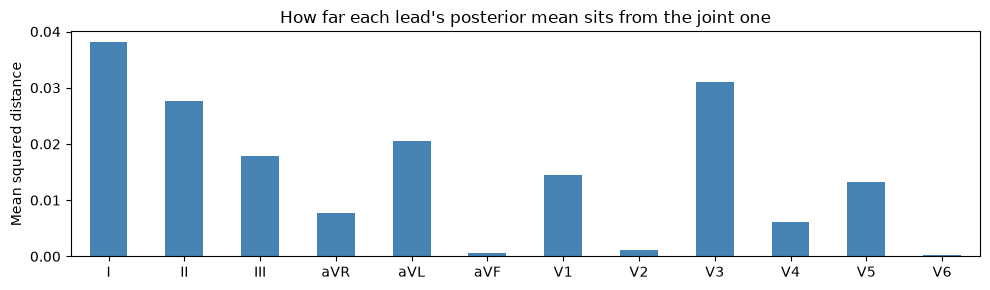

In [8]:
from kalecardiac.auto import get_dataloader
from kalecardiac.interpret import collect_latents

loader = get_dataloader(cfg_pt, pretrain_set, cfg_pt.SOLVER.BATCH_SIZE)
_, joint, per_lead = collect_latents(pretrained, loader, per_modality=True)
distance = pd.Series({lead: np.mean((mean - joint) ** 2) for lead, mean in per_lead.items()})

ax = distance.plot.bar(figsize=(10, 3), color="steelblue", rot=0)
ax.set(ylabel="Mean squared distance", title="How far each lead's posterior mean sits from the joint one")
plt.tight_layout()
plt.show()

## Step 2: Multimodal Fine-tuning

The pretrained lead encoders are fine-tuned on the labelled ECGs in `kalecardiac_finetuning` to classify each subject: **0** healthy, **1** cardiothoracic abnormality. By default they read only the **six limb leads**, as a low-cost recorder captures them. This is the 6L-ECG setting LS-EMVAE was designed for: pretrained on twelve leads and fine-tuned on six, with each of the six keeping the encoder it learned alongside the others. `USE_12_LEADS = True`, in the configuration below, fine-tunes on all twelve instead (12L-ECG).

### Configuration

Fine-tuning starts from the pretrained model, so its configuration file, `configs/config_lsemvae_finetune.yaml`, is merged onto the pretraining configuration. It adds the labelled dataset, the leads used for fine-tuning (the six limb leads; `USE_12_LEADS` below switches to all twelve), the endpoint, the train/validation/test split and the fine-tuning schedule.

Change a setting in the file, or override it in the cell below.

In [9]:
from kalecardiac.loaddata import LIMB_LEADS, STANDARD_12_LEAD

# Fine-tuning starts from the pretrained model, and so from its configuration.
cfg_ft = cfg_pt.clone()
cfg_ft.merge_from_file("configs/config_lsemvae_finetune.yaml")

# ------ Hyperparameters to play with -----
# The task's leads: False fine-tunes on the six limb leads (6L-ECG), as the published model is; True on all twelve.
USE_12_LEADS = False
cfg_ft.ECG.LEADS = list(STANDARD_12_LEAD if USE_12_LEADS else LIMB_LEADS)
cfg_ft.FINETUNE.MAX_EPOCHS = 20
cfg_ft.FINETUNE.BATCH_SIZE = 4
cfg_ft.MODEL.HEAD_HIDDEN = [128]

# ------ Your own data -----
# cfg_ft.DATASET.ROOT = "/path/to/your/finetuning_data"  # holds ECG/ and labels.csv
# cfg_ft.ENDPOINT.LABEL_COLUMN = "label"  # the column of labels.csv holding each subject's class

print(f"DATASET.ROOT: {cfg_ft.DATASET.ROOT}")
print(f"ECG.LEADS: {list(cfg_ft.ECG.LEADS)} -- {len(cfg_ft.ECG.LEADS)} of the {len(cfg_pt.ECG.LEADS)} pretrained")
print(f"ENDPOINT: {cfg_ft.ENDPOINT.NAME}, the {cfg_ft.ENDPOINT.LABEL_COLUMN!r} column of labels.csv\n")
print(f"FINETUNE:\n{cfg_ft.FINETUNE}")

DATASET.ROOT: data/kalecardiac_finetuning
ECG.LEADS: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF'] -- 6 of the 12 pretrained
ENDPOINT: cardiothoracic_abnormality, the 'label' column of labels.csv

FINETUNE:
BASE_LR: 0.001
BATCH_SIZE: 4
MAX_EPOCHS: 20


### Data loading

The labelled cohort has the pretraining layout plus `labels.csv`, with one row per subject. Its ECGs load through the same DICOM source and transform, because the pretrained encoders expect exactly this input shape, taking only the leads named in `cfg_ft.ECG.LEADS`; the labels are an ordinary table.

**Estimated runtime:** 1 second

In [10]:
ecg_ft = ECGFileSource.from_dicom(Path(cfg_ft.DATASET.ROOT, "ECG"), select=cfg_ft.ECG.LEADS, transform=ecg_transform)
labels = pd.read_csv(Path(cfg_ft.DATASET.ROOT, "labels.csv"))

print(ecg_ft)
labels.head()

ECGFileSource(20 subjects | leads=['I', 'II', 'III', 'aVR', 'aVL', 'aVF'] | shape=6x5000 | 500 Hz)


,subject_id,label
0,PHD_1,0
1,PHD_2,1
2,PHD_3,0
3,PHD_4,1
4,PHD_5,0


### Data preparation

`get_lead_sources` splits the fine-tuning leads into one modality each, as in pretraining, and three calls, each reading `cfg_ft`, turn the labels into a fine-tuning task:

- `derive_endpoint` reads each subject's class from `ENDPOINT.LABEL_COLUMN`, dropping a subject without a label rather than assuming it is negative.
- `get_endpoint_target` makes the class the supervision target that every batch carries.
- `get_folds` divides the subjects into training, validation and test sets, stratified by label, with no subject in two sets. 20% of the subjects are held out for testing, and the validation set that selects the checkpoint is drawn from the rest, never from the test set.

The class weight used by the loss is computed from the training set alone.

**Estimated runtime:** 1 second

In [11]:
from kalecardiac.auto import derive_endpoint, get_endpoint_target, get_folds

finetune_leads = get_lead_sources(ecg_ft, leads=cfg_ft.ECG.LEADS)
table = derive_endpoint(cfg_ft, labels)
target = get_endpoint_target(cfg_ft, table, id_column="subject_id")
fold = get_folds(cfg_ft, table)[0]
print(f"modalities: {list(finetune_leads)}")
print(
    f"{len(fold.train_ids)} subjects to train on, {len(fold.val_ids)} to validate on, {len(fold.test_ids)} to test on"
)

modalities: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF']
13 subjects to train on, 3 to validate on, 4 to test on


### Multimodal fine-tuning

`fine_tune`, in `kalecardiac.auto`, fine-tunes as the published LS-EMVAE does: it keeps the pretrained encoder of each lead it is given frozen as a feature extractor, and trains a classification head (one hidden layer of 128 units, with dropout) on those leads' concatenated posterior means. The encoders of leads it is not given are not used. HiME, the shared decoder and the alignment term did their work in pretraining: they shaped every lead's encoder so that its mean already lies in coordinates shared by all the leads, which is what lets six of the twelve encoders carry the task on their own. The head, the loss and the positive class's weight follow from the endpoint and the training labels. After training, the checkpoint with the best validation score is restored and the test subjects are scored.

**Estimated runtime:** 1 minute

In [12]:
from kalecardiac.auto import fine_tune

set_seed(cfg_ft.SOLVER.SEED)
result = fine_tune(cfg_ft, pretrained, finetune_leads, target, fold, cfg_ft.OUTPUT.OUT_DIR)

## Step 3: Evaluation

`fine_tune` scores the held-out test subjects with `score_predictions`, which chooses the metrics suited to the endpoint; for a binary endpoint, these come from `binary_metrics` in `kalecardiac.evaluate`:

- **Accuracy:** the proportion of subjects classified correctly.
- **AUROC:** the area under the receiver operating characteristic curve, which measures how well the scores rank positive subjects above negative ones across all thresholds.
- **MCC:** the Matthews correlation coefficient, which remains informative when the classes are imbalanced.
- **Sensitivity** and **specificity:** the proportions of positive and of negative subjects classified correctly.

AUROC does not depend on a decision threshold, whereas accuracy, MCC, sensitivity and specificity are computed at a threshold of 0.5, so a model can rank subjects well while its scores still fall on one side of that threshold. The predictions are kept for each subject, so they can be inspected or scored again at another threshold.

In [13]:
metrics = pd.Series(result.metrics)[["accuracy", "roc_auc", "mcc", "sensitivity", "specificity"]].astype(float)
metrics.rename({"roc_auc": "AUROC", "mcc": "MCC"}).round(3).to_frame("test")

,test
accuracy,1.0
AUROC,1.0
MCC,1.0
sensitivity,1.0
specificity,1.0


In [14]:
predictions = pd.DataFrame(result.predictions.rows())
predictions.assign(probability=1 / (1 + np.exp(-predictions["score"]))).round(3)

,subject_id,split,fold,score,label,probability
0,PHD_13,test,0,-1.071,0.0,0.255
1,PHD_15,test,0,1.753,1.0,0.852
2,PHD_6,test,0,1.753,1.0,0.852
3,PHD_7,test,0,-2.851,0.0,0.055


**With fewer leads.** A recorder may capture fewer leads than the model was fine-tuned on: a single-lead wearable, for example, records lead I alone. `progressive_ablation`, in `kalecardiac.interpret`, withholds the leads one after another and scores the test subjects again at each step. A lead is withheld through the presence mask, so the model sees an absent lead, exactly as from a recorder that never captured it, rather than a flat line, and each remaining lead's encoder works without the others.

In [15]:
from kalecardiac.auto import get_ablation_metric
from kalecardiac.interpret import progressive_ablation

# Withheld from the last lead backwards, leaving the first: lead I, which a single-lead wearable records.
WITHHOLD = list(reversed(cfg_ft.ECG.LEADS[1:]))

_, metric, key = get_ablation_metric(cfg_ft)
steps = progressive_ablation(result.model, result.test_loader, metric, key, order=WITHHOLD)
pd.DataFrame([{"leads": " ".join(step["present"]), "test AUROC": step["score"]} for step in steps]).round(3)

,leads,test AUROC
0,I II III aVR aVL aVF,1.0
1,I II III aVR aVL,1.0
2,I II III aVR,1.0
3,I II III,1.0
4,I II,1.0
5,I,1.0


## Step 4: Interpretation

Two questions, both answered from the fine-tuned model:

- **Which leads does the model rely on?** `interpret_model`, in `kalecardiac.auto`, runs integrated gradients over the test subjects and reports each lead's *attribution ratio*, the share of its time points that are strongly attributed, together with that ratio's share of the total. It then withholds each lead in turn, through the presence mask, and scores the test set again; a lead whose removal costs little is one the other leads can stand in for. The two measures can disagree, and the disagreement is informative: a lead can be strongly attributed and still be redundant, because another lead carries the same information, as leads, all projections of the same cardiac activity, often do.
- **Where in each lead?** `modality_attributions`, in `kalecardiac.interpret`, attributes one subject's prediction to every time point of each of its leads with [Captum](https://captum.ai)'s integrated gradients [2], and `normalize_attribution` rescales the leads' maps together to [0, 1], so that the leads can be compared and the regions above a threshold highlighted.

**Estimated runtime:** 10 seconds

In [16]:
from kalecardiac.auto import interpret_model

summary = interpret_model(cfg_ft, result.model, result.test_loader, cfg_ft.OUTPUT.OUT_DIR)
ablation = summary.get("ablation", {})
lead_importance = pd.DataFrame(summary["attribution"]).T
lead_importance["test AUROC without it"] = [ablation.get(f"without_{lead}") for lead in lead_importance.index]
print(f"Test AUROC with all {len(lead_importance)} leads: {ablation.get('full', float('nan')):.3f}")
lead_importance.round(3)

Test AUROC with all 6 leads: 1.000


,ratio,share,test AUROC without it
I,0.002,0.089,1.0
II,0.001,0.067,1.0
III,0.002,0.113,1.0
aVR,0.004,0.210,1.0
aVL,0.002,0.135,1.0
aVF,0.007,0.385,1.0


One test subject's prediction, attributed to each of its leads.

In [17]:
import torch

from kalecardiac.interpret import modality_attributions, normalize_attribution
from kalecardiac.loaddata import collate_subjects

# Change these to explain another test subject or lead, to move the threshold, or to widen the zoom.
SAMPLE_IDX, LEAD = 0, "II"
THRESHOLD, ZOOM_SECONDS = 0.75, 0.5

sample = collate_subjects([result.test_loader.dataset[SAMPLE_IDX]])
attributions = modality_attributions(result.model.model, sample.modalities, present=sample.present)

# One row per lead. The maps are normalized together, so one lead's importance can be read against another's.
leads = list(cfg_ft.ECG.LEADS)
ecg_signals = np.stack([sample.modalities[lead][0, 0].numpy() for lead in leads])
ecg_importance = normalize_attribution(np.stack([attributions[lead][0, 0] for lead in leads]))
ecg_time = np.arange(ecg_signals.shape[1]) / cfg_ft.ECG.SAMPLING_RATE

probability = torch.sigmoid(result.model.predict(sample).prediction).item()
print(
    f"{sample.subject_id[0]}: label {int(sample.target['label'])}, predicted probability of a cardiothoracic "
    f"abnormality {probability:.2f}"
)

PHD_13: label 0, predicted probability of a cardiothoracic abnormality 0.26


**Full ECG view:** each lead over the full ten seconds, with the time points whose attribution exceeds the threshold drawn in red.

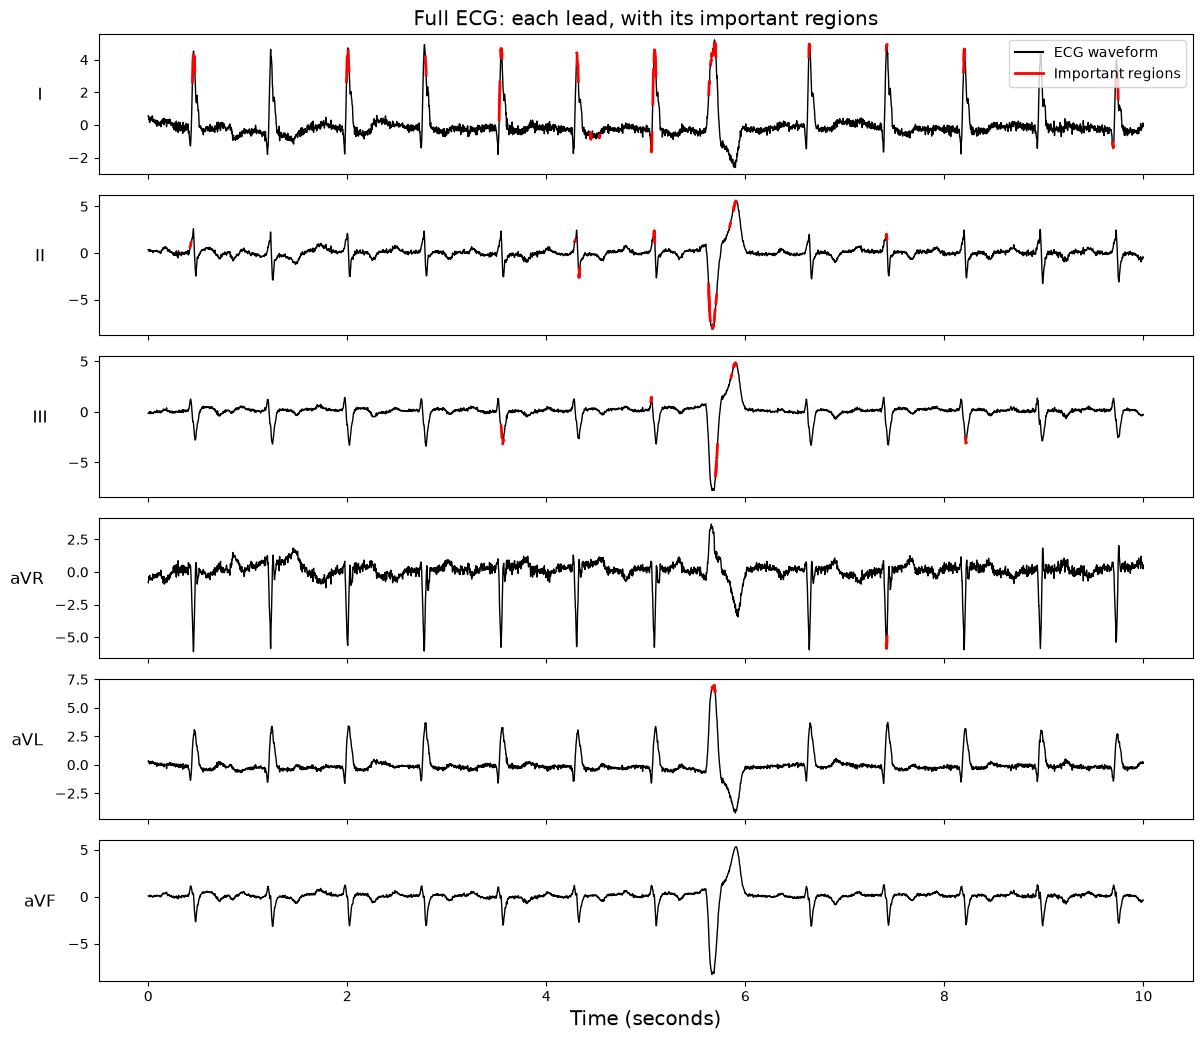

In [18]:
from matplotlib.lines import Line2D


def plot_leads(names: list[str], window: slice, title: str, width: float = 1.0):
    fig, axes = plt.subplots(len(names), 1, figsize=(12, 1.5 * len(names) + 1.5), sharex=True, squeeze=False)
    for ax, name in zip(axes[:, 0], names, strict=True):
        signal, importance = ecg_signals[leads.index(name), window], ecg_importance[leads.index(name), window]
        ax.plot(ecg_time[window], signal, color="black", linewidth=width)
        for index in np.flatnonzero(importance >= THRESHOLD):
            stretch = slice(max(index - 2, 0), index + 3)
            ax.plot(ecg_time[window][stretch], signal[stretch], color="red", linewidth=2 * width)
        ax.set_ylabel(name, rotation=0, labelpad=20, fontsize="large")
    axes[-1, 0].set_xlabel("Time (seconds)", fontsize="x-large")
    legend = [Line2D([], [], color="black"), Line2D([], [], color="red", linewidth=2)]
    axes[0, 0].legend(legend, ["ECG waveform", "Important regions"], fontsize="medium", loc="best")
    axes[0, 0].set_title(title, fontsize="x-large")
    plt.tight_layout()
    plt.show()


plot_leads(leads, slice(None), "Full ECG: each lead, with its important regions")

**Zoomed-in ECG segment:** half a second of one lead, lead II by default, around its most strongly attributed time point, in finer detail.

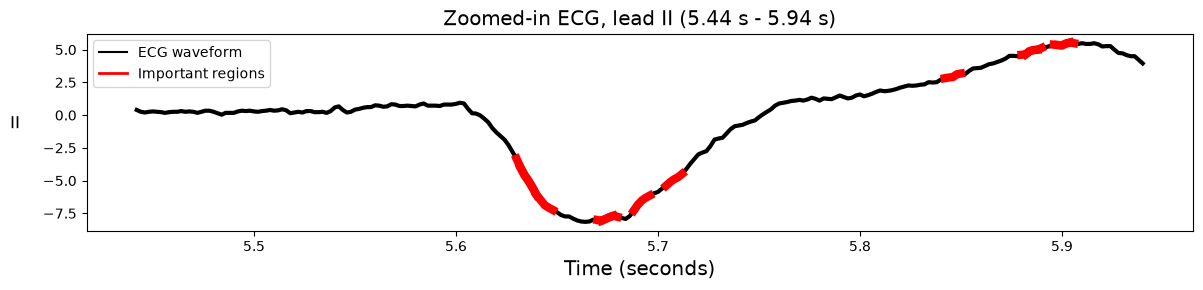

In [19]:
centre = ecg_time[np.argmax(ecg_importance[leads.index(LEAD)])]
first = max(centre - ZOOM_SECONDS / 2, 0.0)
last = first + ZOOM_SECONDS
window = slice(int(first * cfg_ft.ECG.SAMPLING_RATE), int(last * cfg_ft.ECG.SAMPLING_RATE))
plot_leads([LEAD], window, f"Zoomed-in ECG, lead {LEAD} ({first:.2f} s - {last:.2f} s)", width=3)

## References

[1] Suvon, M. N. I., et al. (2025). Multimodal latent fusion of ECG leads for early assessment of pulmonary hypertension. *arXiv preprint arXiv:2503.13470*. Reference implementation: [github.com/Shef-AIRE/LS-EMVAE](https://github.com/Shef-AIRE/LS-EMVAE).

[2] Sundararajan, M., Taly, A., & Yan, Q. (2017). Axiomatic attribution for deep networks. In *International Conference on Machine Learning* (pp. 3319-3328).

[3] Lu, H., Liu, X., Zhou, S., Turner, R., Bai, P., Koot, R. E., ... & Xu, H. (2022). PyKale: Knowledge-aware machine learning from multiple sources in Python. In *Proceedings of the 31st ACM International Conference on Information & Knowledge Management* (pp. 4274-4278).